### Приверка идеи построение графика «Уровень оттока по типу контракта»

Покажем бизнесу кто из клиентов находится в зоне риска.

--- 1. Загрузка и подготовка данных ---
✅ Модель найдена, загружаем...

--- 3. Построение графика оттока по контрактам ---


C:\Users\jumpe\AppData\Local\Temp\ipykernel_24368\3514321351.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=churn_rate.index, y=churn_rate.values, palette='Reds_r')


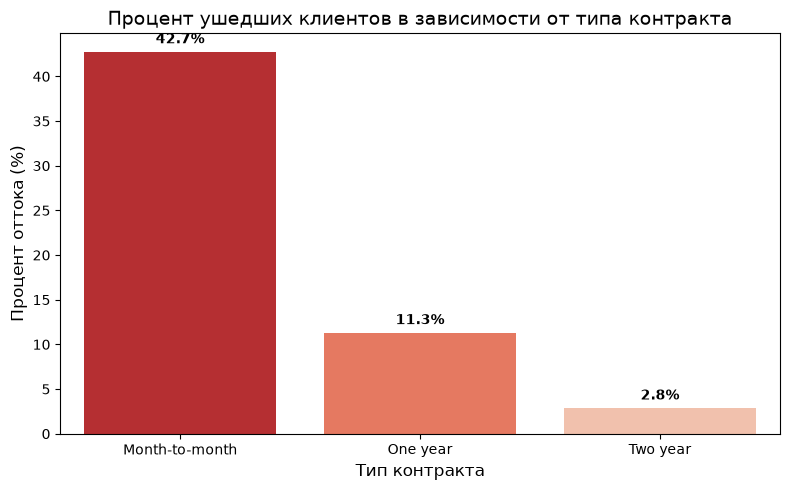


--- 4. Построение портрета уходящего клиента ---


C:\Users\jumpe\AppData\Local\Temp\ipykernel_24368\3514321351.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df, x='Churn', y='MonthlyCharges', palette='Set2')
C:\Users\jumpe\AppData\Local\Temp\ipykernel_24368\3514321351.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df, x='Churn', y='tenure', palette='Set2')


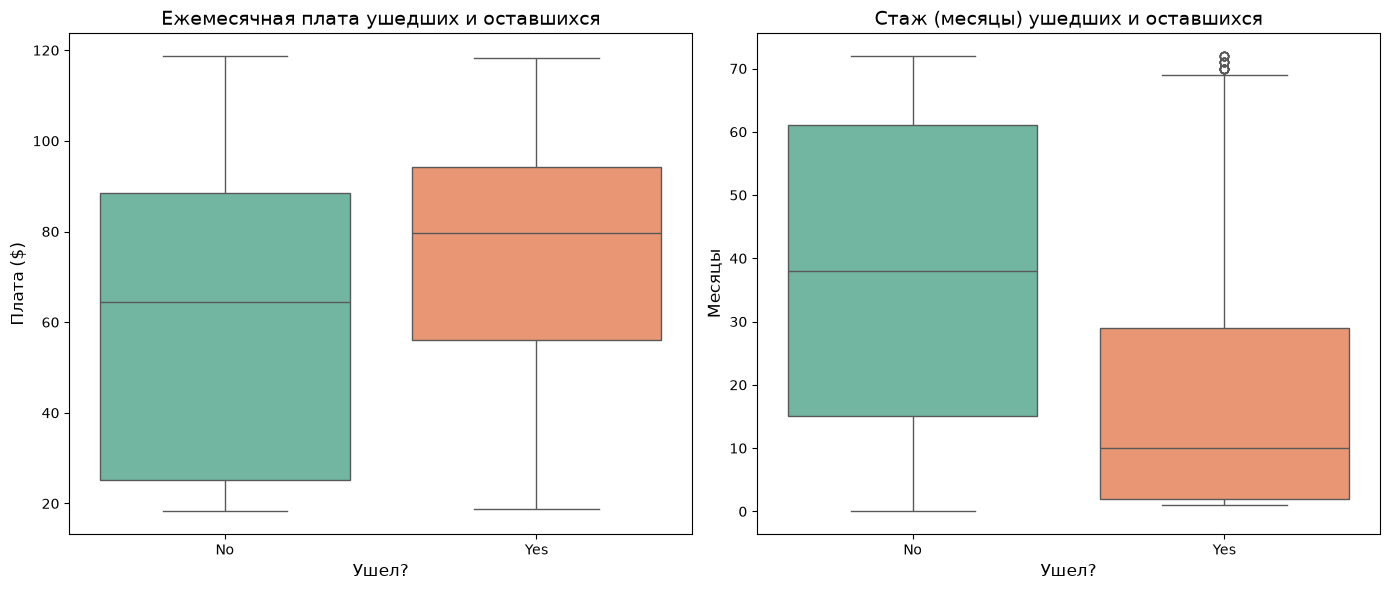

Background dataset has 7043 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=7043 when initializing the masker.



--- 5. Построение графика Топ-10 факторов (SHAP Bar) ---


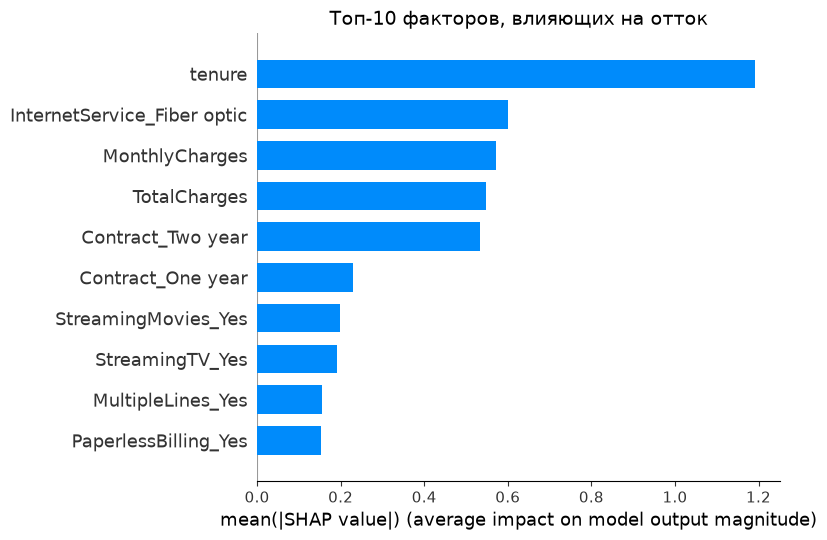


--- 6. Формирование списка клиентов в зоне риска ---
✅ Найдено клиентов с риском ухода > 70%: 1774

Топ-5 клиентов для звонка отдела удержания:
CustomerID  Churn_Probability
9497-QCMMS           0.936600
9300-AGZNL           0.936034
7024-OHCCK           0.935255
4424-TKOPW           0.934734
2720-WGKHP           0.934271

🎉 Все результаты успешно сгенерированы и сохранены в папку reports!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Создаем папки на случай, если их нет
os.makedirs('../models', exist_ok=True)
os.makedirs('../reports', exist_ok=True)

print("--- 1. Загрузка и подготовка данных ---")
df = pd.read_csv('../data/processed/cleaned_data.csv')
X = df.drop(columns=['Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})
X_encoded = pd.get_dummies(X, drop_first=True)

# --- 2. Проверка и обучение модели ---
model_path = '../models/churn_model.pkl'
if not os.path.exists(model_path):
    print("Модель не найдена. Обучаем новую...")
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
    )
    model.fit(X_encoded, y)
    joblib.dump(model, model_path)
    print("✅ Модель обучена и сохранена.")
else:
    print("✅ Модель найдена, загружаем...")
    model = joblib.load(model_path)

# --- 3. График: Уровень оттока по типу контракта ---
print("\n--- 3. Построение графика оттока по контрактам ---")
churn_rate = df.groupby('Contract')['Churn'].value_counts(normalize=True).unstack()['Yes'] * 100
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=churn_rate.index, y=churn_rate.values, palette='Reds_r')
plt.title('Процент ушедших клиентов в зависимости от типа контракта', fontsize=14)
plt.ylabel('Процент оттока (%)', fontsize=12)
plt.xlabel('Тип контракта', fontsize=12)
for i, v in enumerate(churn_rate.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/churn_by_contract.png', dpi=300)
plt.show()

# --- 4. График: Портрет уходящего клиента ---
print("\n--- 4. Построение портрета уходящего клиента ---")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(ax=axes[0], data=df, x='Churn', y='MonthlyCharges', palette='Set2')
axes[0].set_title('Ежемесячная плата ушедших и оставшихся', fontsize=14)
axes[0].set_ylabel('Плата ($)', fontsize=12)
axes[0].set_xlabel('Ушел?', fontsize=12)
sns.boxplot(ax=axes[1], data=df, x='Churn', y='tenure', palette='Set2')
axes[1].set_title('Стаж (месяцы) ушедших и оставшихся', fontsize=14)
axes[1].set_ylabel('Месяцы', fontsize=12)
axes[1].set_xlabel('Ушел?', fontsize=12)
plt.tight_layout()
plt.savefig('../reports/churn_profile.png', dpi=300)
plt.show()

# --- 5. Упрощенный график SHAP (Бар-чарт) ---
print("\n--- 5. Построение графика Топ-10 факторов (SHAP Bar) ---")
log_reg = model.named_steps['logisticregression']
scaler = model.named_steps['standardscaler']
X_scaled = scaler.transform(X_encoded)

explainer = shap.LinearExplainer(log_reg, X_scaled)
shap_values = explainer.shap_values(X_scaled)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_encoded, plot_type="bar", show=False, max_display=10)
plt.title("Топ-10 факторов, влияющих на отток", fontsize=14)
plt.tight_layout()
plt.savefig('../reports/top_factors_bar.png', dpi=300)
plt.show()

# --- 6. Таблица: Список клиентов в зоне риска ---
print("\n--- 6. Формирование списка клиентов в зоне риска ---")
df_original = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
probabilities = model.predict_proba(X_encoded)[:, 1]

risk_df = pd.DataFrame({
    'CustomerID': df_original['customerID'],
    'Churn_Probability': probabilities
})

high_risk = risk_df[risk_df['Churn_Probability'] > 0.70].sort_values(by='Churn_Probability', ascending=False)
high_risk.to_csv('../reports/high_risk_customers.csv', index=False)

print(f"✅ Найдено клиентов с риском ухода > 70%: {len(high_risk)}")
print("\nТоп-5 клиентов для звонка отдела удержания:")
print(high_risk.head(5).to_string(index=False))

print("\n🎉 Все результаты успешно сгенерированы и сохранены в папку reports!")